In [12]:
# Cell 1: load data, train/val/test split, helpers
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F, time
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from IPython.display import display

dev = "cuda" if torch.cuda.is_available() else "cpu"
D = np.load("/content/wm_data.npz")
roi = D["roi"]; print("crop zone:", roi)
assert roi[1] < 300, "old data file: replace it before training"
frames = torch.from_numpy(D["frames"]).to(dev)      # (N, S, S, 3) uint8
hand = torch.from_numpy(D["hand"]).to(dev)          # (N, 4): pinch x, pinch y, opening, hand present
ep_start, ep_pos, names = D["ep_start"], D["ep_pos"], [str(n) for n in D["names"]]
N, S = frames.shape[0], frames.shape[1]
ep_end = np.r_[ep_start[1:], N]
rep = np.array([int(n[-1]) for n in names])
is_test = np.array([p in {3, 6} for p in ep_pos])   # start positions 03 and 06 are never seen in training
is_val = (~is_test) & (rep == 5)

crop zone: [ 264   59 2160 2608]


In [21]:
print(dev, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")
print(is_train.sum(), "train videos,", is_val.sum(), "val videos,", is_test.sum(), "test videos")

cuda Tesla T4
22 train videos, 6 val videos, 10 test videos


In [13]:
# Cell 2: model, loss, training
def block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.GroupNorm(8, o), nn.GELU(),
                         nn.Conv2d(o, o, 3, padding=1), nn.GroupNorm(8, o), nn.GELU())

class WM(nn.Module):
    """Small U-Net that predicts the change from the current frame, given the hand maps."""
    def __init__(s, c=32):
        super().__init__()
        s.e1, s.e2, s.e3, s.mid = block(7, c), block(c, 2 * c), block(2 * c, 4 * c), block(4 * c, 4 * c)
        s.d2, s.d1 = block(6 * c, 2 * c), block(3 * c, c)
        s.out = nn.Conv2d(c, 3, 3, padding=1)
        nn.init.zeros_(s.out.weight); nn.init.zeros_(s.out.bias)      # starts as "copy the last frame"
    def forward(s, x, cd):
        a = s.e1(torch.cat([x, cd], 1))
        b = s.e2(F.avg_pool2d(a, 2))
        m = s.mid(s.e3(F.avg_pool2d(b, 2)))
        u = s.d2(torch.cat([F.interpolate(m, scale_factor=2), b], 1))
        u = s.d1(torch.cat([F.interpolate(u, scale_factor=2), a], 1))
        return (x + s.out(u)).clamp(0, 1)

def rollout(model, x0, hseq, use_action=True):    # predict K frames in a row, feeding back its own outputs
    x, out = x0, []
    for k in range(hseq.shape[1] - 1):
        x = model(x, cond(hseq[:, k], hseq[:, k + 1], use_action))
        out.append(x)
    return torch.stack(out, 1)

def loss_fn(pred, tgt, prev):    # L1, pixels that change weighted 6x
    mov = ((tgt - prev).abs().mean(2, keepdim=True) > 0.04).float()
    return ((1 + 5 * mov) * (pred - tgt).abs()).mean()

def train(use_action=True, steps=4000, K=4, bs=64, lr=1e-3, tag="wm"):
    torch.manual_seed(0)
    model = WM().to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps)
    tr, va = starts(is_train, K), starts(is_val, K, stride=3)
    g = torch.Generator().manual_seed(1)
    vsel = va[torch.randperm(len(va), generator=g)[:512].to(dev)]       # same validation windows at every check
    best_v, best_state, best_it = 1e9, None, 0
    t0 = time.time()
    for it in range(1, steps + 1):
        model.train()
        f, h = get(tr[torch.randint(len(tr), (bs,), device=dev)], K)
        gain = 0.85 + 0.3 * torch.rand(bs, 1, 1, 1, 1, device=dev)      # light brightness augmentation
        bias = 0.1 * (torch.rand(bs, 1, 1, 1, 1, device=dev) - 0.5)
        f = (f * gain + bias).clamp(0, 1)
        loss = loss_fn(rollout(model, f[:, 0], h, use_action), f[:, 1:], f[:, :-1])
        opt.zero_grad(set_to_none=True); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
        if it % 500 == 0 or it == steps or it == 50:
            model.eval()
            with torch.no_grad():
                f, h = get(vsel, K)
                p = rollout(model, f[:, 0], h, use_action)
                v = (p - f[:, 1:]).abs().mean().item()
                c = (f[:, :1] - f[:, 1:]).abs().mean().item()
            if v < best_v:
                best_v, best_it = v, it
                best_state = {k: x.detach().clone() for k, x in model.state_dict().items()}
            print(f"step {it:5d} | loss {loss.item():.4f} | val: model {v:.4f} vs copy-last {c:.4f} | {time.time() - t0:.0f} s", flush=True)
    model.load_state_dict(best_state)
    torch.save(model.state_dict(), f"/content/{tag}.pt")
    print(f"best validation checkpoint: step {best_it} (error {best_v:.4f})")
    return model

In [14]:
# Cell 3: evaluation by horizon, curves, visual rollouts
@torch.no_grad()
def evaluate(model, use_action=True, swap=False, H=20, stride=5):
    model.eval()
    te = np.where(is_test)[0]
    fm, fc, nm, nc, dn = [], [], 0, 0, 0
    for j, e in enumerate(te):
        e2 = te[(j + 1) % len(te)]
        L, L2 = ep_end[e] - ep_start[e], ep_end[e2] - ep_start[e2]
        ts = np.arange(0, L - H, stride)
        f, h = get(torch.tensor(ep_start[e] + ts, device=dev), H)
        if swap:  # replace the hand by the hand of another test video
            idx2 = ep_start[e2] + np.minimum(ts, L2 - H - 1)
            _, h = get(torch.tensor(idx2, device=dev), H)
        p = rollout(model, f[:, 0], h, use_action)
        tgt = f[:, 1:]
        cp = f[:, :1].expand_as(tgt)
        # pixels that really change (used for measurement only)
        mov = ((tgt - f[:, :1]).abs().mean(2) > 0.04).float()
        dm = (p - tgt).abs().mean(2)
        dc = (cp - tgt).abs().mean(2)
        fm.append(dm.mean((2, 3)))
        fc.append(dc.mean((2, 3)))
        nm = nm + (dm * mov).sum((0, 2, 3))
        nc = nc + (dc * mov).sum((0, 2, 3))
        dn = dn + mov.sum((0, 2, 3))
    d = dn.clamp(min=1)
    whole_model = torch.cat(fm).mean(0).cpu().numpy()
    whole_copy = torch.cat(fc).mean(0).cpu().numpy()
    return whole_model, whole_copy, (nm / d).cpu().numpy(), (nc / d).cpu().numpy()


def report(m_act, m_noact):
    res = {
        "model (real hand)": evaluate(m_act),
        "model (hand from another video)": evaluate(m_act, swap=True),
        "model without action": evaluate(m_noact, use_action=False),
    }
    cf, cm = res["model (real hand)"][1], res["model (real hand)"][3]
    t = (np.arange(20) + 1) * 0.1
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for name, (a, _, b, _) in res.items():
        ax[0].plot(t, a, label=name)
        ax[1].plot(t, b, label=name)
    ax[0].plot(t, cf, "k--", label="copy the last frame")
    ax[1].plot(t, cm, "k--")

In [19]:
# Cell 4: object fidelity: where is the green box, and does the model move it with the hand?
GREEN_MARGIN, GREEN_MIN, MIN_PIX = 0.07, 0.20, 3


def green_centroid(x):
    # x: (B, T, 3, S, S) in [0, 1] -> centroid (B, T, 2) in pixels, found (B, T)
    r, g, b = x[:, :, 0], x[:, :, 1], x[:, :, 2]
    m = ((g - torch.maximum(r, b)) > GREEN_MARGIN) & (g > GREEN_MIN)
    n = m.sum((2, 3)).float()
    cx = (m.float() * xx).sum((2, 3)) / n.clamp(min=1)
    cy = (m.float() * yy).sum((2, 3)) / n.clamp(min=1)
    return torch.stack([cx, cy], -1), n >= MIN_PIX


def check_green(e=None, n=6, a=0.0, b=1.0):
    # real frames of one video (from fraction a to b) with the detected box (red square)
    e = np.where(is_train)[0][0] if e is None else e
    L = ep_end[e] - ep_start[e]
    lo, hi = ep_start[e] + int(a * L), ep_start[e] + int(b * L) - 1
    idx = torch.tensor(np.linspace(lo, hi, n).astype(int), device=dev)
    x = frames[idx].permute(0, 3, 1, 2).float().div(255).unsqueeze(0)
    c, ok = green_centroid(x)
    tiles = []
    for k in range(n):
        im = (x[0, k].permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8).copy()
        im = np.kron(im, np.ones((4, 4, 1), np.uint8))
        if ok[0, k]:
            cx, cy = (c[0, k] * 4 + 2).int().tolist()
            im[max(cy - 3, 0):cy + 4, max(cx - 3, 0):cx + 4] = [255, 0, 0]
        tiles.append(im)
    print("box detected in", int(ok.sum()), "frames out of", n)
    display(Image.fromarray(np.hstack(tiles)))


@torch.no_grad()
def object_fidelity(model, use_action=True, swap=False, H=20, stride=5, move_px=3.0):
    model.eval()
    te = np.where(is_test)[0]
    acc = {k: dict(em=[], ec=[], found=[], n=0) for k in (5, 10, 20)}
    for j, e in enumerate(te):
        e2 = te[(j + 1) % len(te)]
        L, L2 = ep_end[e] - ep_start[e], ep_end[e2] - ep_start[e2]
        ts = np.arange(0, L - H, stride)
        f, h = get(torch.tensor(ep_start[e] + ts, device=dev), H)
        if swap:
            idx2 = ep_start[e2] + np.minimum(ts, L2 - H - 1)
            _, h = get(torch.tensor(idx2, device=dev), H)
        p = rollout(model, f[:, 0], h, use_action)
        c0, ok0 = green_centroid(f[:, :1])
        c0, ok0 = c0[:, 0], ok0[:, 0]
        cr, okr = green_centroid(f[:, 1:])
        cp, okp = green_centroid(p)
        for k in acc:
            real_k, ok_real = cr[:, k - 1], okr[:, k - 1]
            # windows where the box really moves
            moving = ok0 & ok_real & ((real_k - c0).norm(dim=1) > move_px)
            if moving.sum() == 0:
                continue
            acc[k]["n"] += int(moving.sum())
            # copy-last error: the box stays where it was
            acc[k]["ec"] += (c0 - real_k).norm(dim=1)[moving].tolist()
            fnd = okp[:, k - 1][moving]
            acc[k]["found"] += fnd.float().tolist()
            err = (cp[:, k - 1] - real_k).norm(dim=1)[moving][fnd]
            acc[k]["em"] += err.tolist()
    return acc


def fidelity_report(m_act, m_noact):
    runs = {
        "real hand": object_fidelity(m_act),
        "hand from another video": object_fidelity(m_act, swap=True),
        "no action": object_fidelity(m_noact, use_action=False),
    }
    for k in (5, 10, 20):
        a = runs["real hand"][k]
        print(f"horizon {k / 10:.1f} s | {a['n']} windows where the box moves"
              f" | copy-last: median error {np.median(a['ec']):.1f} px")
        for name, r in runs.items():
            x = r[k]
            med = np.median(x["em"]) if x["em"] else float("nan")
            pct = 100 * np.mean(x["found"]) if x["found"] else 0
            print(f"    {name:26s} median error {med:.1f} px | box found in {pct:.0f} % of predictions")

box detected in 6 frames out of 6


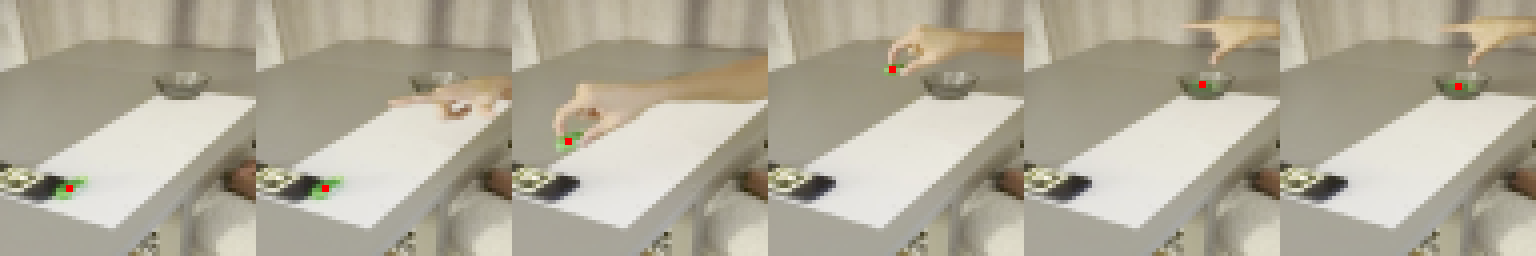

box detected in 5 frames out of 6


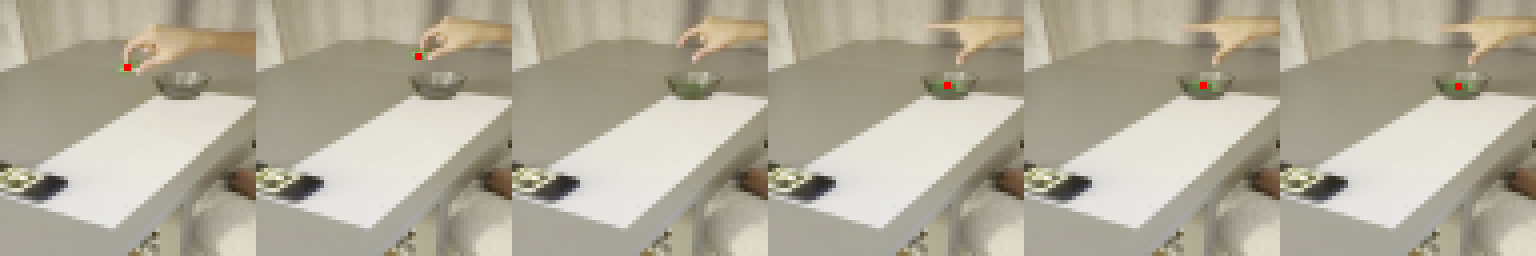

box detected in 2 frames out of 6


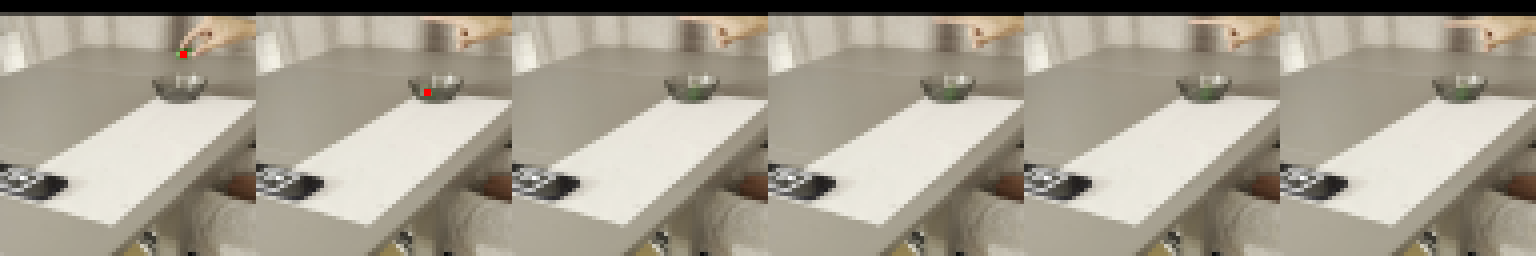

In [20]:
# Cell 5: sanity check of the box detector: the red square must sit on the green box
check_green()
check_green(a=0.6, b=1.0)
check_green(np.where(is_test)[0][0], a=0.6, b=1.0)

In [22]:
# Cell 6: train the model that sees the hand (about 23 minutes)
m_act = train(True, tag="wm_act")

step    50 | loss 0.0111 | val: model 0.0048 vs copy-last 0.0043 | 19 s
step   500 | loss 0.0095 | val: model 0.0040 vs copy-last 0.0043 | 181 s
step  1000 | loss 0.0069 | val: model 0.0034 vs copy-last 0.0043 | 361 s
step  1500 | loss 0.0051 | val: model 0.0031 vs copy-last 0.0043 | 541 s
step  2000 | loss 0.0037 | val: model 0.0026 vs copy-last 0.0043 | 719 s
step  2500 | loss 0.0032 | val: model 0.0025 vs copy-last 0.0043 | 898 s
step  3000 | loss 0.0037 | val: model 0.0025 vs copy-last 0.0043 | 1078 s
step  3500 | loss 0.0028 | val: model 0.0024 vs copy-last 0.0043 | 1258 s
step  4000 | loss 0.0026 | val: model 0.0024 vs copy-last 0.0043 | 1437 s
best validation checkpoint: step 4000 (error 0.0024)


In [23]:
# Cell 7: train the model without the hand (about 23 minutes)
m_noact = train(False, tag="wm_noact")

step    50 | loss 0.0110 | val: model 0.0046 vs copy-last 0.0043 | 18 s
step   500 | loss 0.0123 | val: model 0.0046 vs copy-last 0.0043 | 181 s
step  1000 | loss 0.0085 | val: model 0.0041 vs copy-last 0.0043 | 360 s
step  1500 | loss 0.0069 | val: model 0.0036 vs copy-last 0.0043 | 538 s
step  2000 | loss 0.0052 | val: model 0.0033 vs copy-last 0.0043 | 718 s
step  2500 | loss 0.0045 | val: model 0.0032 vs copy-last 0.0043 | 897 s
step  3000 | loss 0.0052 | val: model 0.0033 vs copy-last 0.0043 | 1076 s
step  3500 | loss 0.0036 | val: model 0.0032 vs copy-last 0.0043 | 1256 s
step  4000 | loss 0.0034 | val: model 0.0033 vs copy-last 0.0043 | 1435 s
best validation checkpoint: step 3500 (error 0.0032)


In [24]:
# Cell 8: error by horizon on the test positions 03 and 06
report(m_act, m_noact)

In [25]:
# Cell 9: is the green box moved along with the hand?
fidelity_report(m_act, m_noact)

horizon 0.5 s | 58 windows where the box moves | copy-last: median error 4.8 px
    real hand                  median error 0.4 px | box found in 93 % of predictions
    hand from another video    median error 5.0 px | box found in 100 % of predictions
    no action                  median error 2.2 px | box found in 97 % of predictions
horizon 1.0 s | 93 windows where the box moves | copy-last: median error 7.4 px
    real hand                  median error 0.5 px | box found in 92 % of predictions
    hand from another video    median error 6.3 px | box found in 100 % of predictions
    no action                  median error 3.9 px | box found in 94 % of predictions
horizon 2.0 s | 119 windows where the box moves | copy-last: median error 10.8 px
    real hand                  median error 0.7 px | box found in 94 % of predictions
    hand from another video    median error 7.6 px | box found in 100 % of predictions
    no action                  median error 6.2 px | box found in 8

pickplace_pos03_rep1 (lignes : réalité / prédiction / prédiction avec la main de pickplace_pos06_rep1)


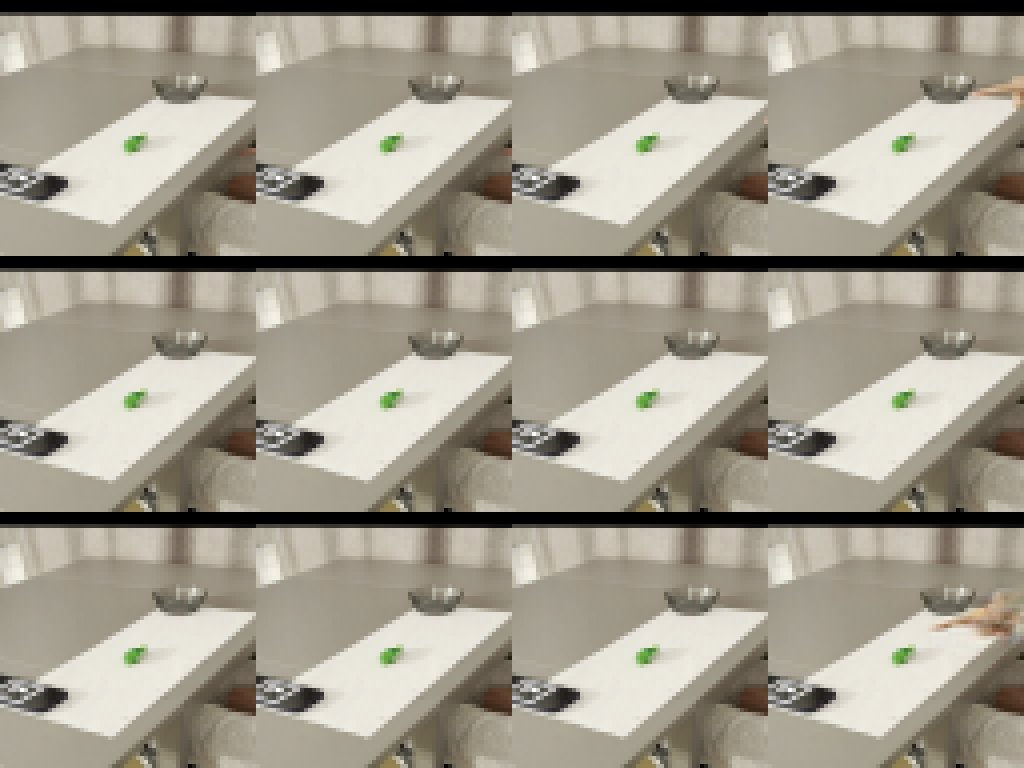

In [26]:
# Cell 10: real / prediction / prediction with the hand of another video
make_rollout(m_act, te[0], te[len(te) // 2])